In [6]:
# Ejemplo de transformación
# Extraído de:
# http://msenux2.redwoods.edu/MathDept/R/TransformingData.php
# Peso en kg
# RMR en kcalorías/día

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import statsmodels.api as sm

archivo = "RMR.csv"  # Ruta al archivo
datos = pd.read_csv(archivo)  # Carga de datos
datos.head()  # Muestra las primeras filas

,peso,rmr
0,8.50,363
1,6.40,293
2,0.85,46
3,8.41,346
4,0.70,54


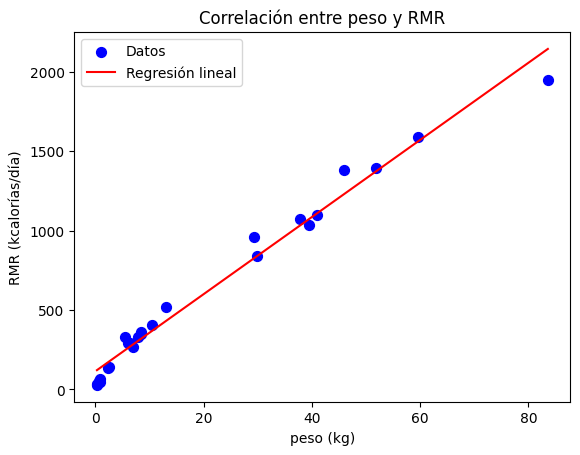

In [3]:
# Estimar el modelo lineal: RMR ~ peso
X = datos["peso"]
y = datos["rmr"]
X_const = sm.add_constant(X)  # Agrega término constante (intercepto)
modelo1 = sm.OLS(y, X_const).fit()

# Graficar los datos
plt.scatter(datos["peso"], datos["rmr"], c='blue', s=50, label='Datos')
plt.title("Correlación entre peso y RMR")
plt.xlabel("peso (kg)")
plt.ylabel("RMR (kcalorías/día)")

# Agregar la recta de regresión
pendiente = modelo1.params["peso"]
intercepto = modelo1.params["const"]
x_vals = pd.Series(sorted(datos["peso"]))
y_vals = intercepto + pendiente * x_vals
plt.plot(x_vals, y_vals, color='red', label='Regresión lineal')

plt.legend()
plt.show()


In [4]:
# Mostrar el resumen del modelo
print(modelo1.summary())


                            OLS Regression Results                            
Dep. Variable:                    rmr   R-squared:                       0.981
Model:                            OLS   Adj. R-squared:                  0.980
Method:                 Least Squares   F-statistic:                     1183.
Date:                Fri, 29 Aug 2025   Prob (F-statistic):           2.77e-21
Time:                        12:26:07   Log-Likelihood:                -143.56
No. Observations:                  25   AIC:                             291.1
Df Residuals:                      23   BIC:                             293.6
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const        113.7272     21.128      5.383      0.0

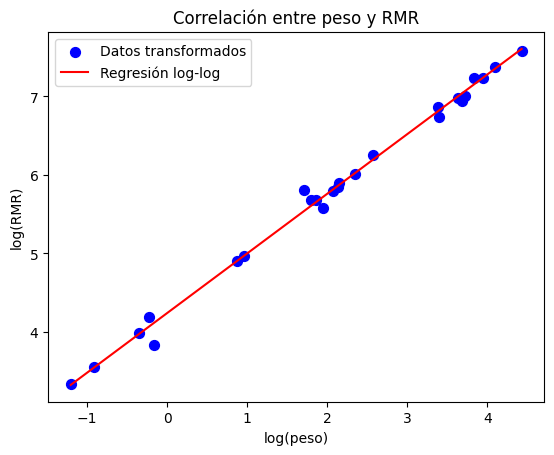

In [10]:
# Transformación logarítmica
log_peso = np.log(datos["peso"])
log_rmr = np.log(datos["rmr"])

# Estimar el modelo lineal: log(RMR) ~ log(peso)
X_log = sm.add_constant(log_peso)
modelo2 = sm.OLS(log_rmr, X_log).fit()

# Graficar los datos transformados
plt.scatter(log_peso, log_rmr, c='blue', s=50, label='Datos transformados')
plt.title("Correlación entre peso y RMR")
plt.xlabel("log(peso)")
plt.ylabel("log(RMR)")

# Agregar la recta de regresión
pendiente = modelo2.params.iloc[1]
intercepto = modelo2.params.iloc[0]
x_vals = np.linspace(log_peso.min(), log_peso.max(), 100)
y_vals = intercepto + pendiente * x_vals
plt.plot(x_vals, y_vals, color='red', label='Regresión log-log')

plt.legend()
plt.show()

In [8]:
# Mostrar el resumen del modelo
print(modelo2.summary())

                            OLS Regression Results                            
Dep. Variable:                    rmr   R-squared:                       0.994
Model:                            OLS   Adj. R-squared:                  0.994
Method:                 Least Squares   F-statistic:                     3810.
Date:                Fri, 29 Aug 2025   Prob (F-statistic):           4.64e-27
Time:                        12:28:24   Log-Likelihood:                 23.041
No. Observations:                  25   AIC:                            -42.08
Df Residuals:                      23   BIC:                            -39.64
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const          4.2409      0.032    130.955      0.0